# BBC News Classification with BERT: Lab
# Solution

## Overview
As a junior data scientist at NewsInsight, a media analytics company, you've been tasked with building an automated news categorization system. Your team needs to classify incoming news articles into appropriate categories to help journalists, researchers, and business analysts quickly find relevant information.

The company receives thousands of articles daily from various sources. Currently, human editors spend significant time manually categorizing these articles, which is time-consuming and inconsistent. Your manager has asked you to develop a machine learning solution that can automatically categorize news articles into predefined categories (business, entertainment, politics, sport, tech).

This project will follow the BERT fine-tuning process you've learned:
1. Understanding data and defining requirements
2. Selecting and preparing the BERT model
3. Data preparation and tokenization
4. Model architecture design
5. Fine-tuning the model
6. Evaluation and refinement

Successfully implementing this system will significantly improve workflow efficiency, allowing editors to focus on content quality rather than manual categorization.

## Part 1: Environment Setup and Data Loading

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import seaborn as sns

# Set random seeds for reproducibility
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

set_seed()

In [2]:
# Load the data from csv file
df = pd.read_csv('bbc_news_data.csv', sep='\t')
df.head()

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


<!-- ## Part 2: Data Exploration and Preprocessing -->

Explore the dataset, displaying basic information and:
- Analyze category distribution
- Check text length distribution
- Train test split data, use 75-25 split

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB


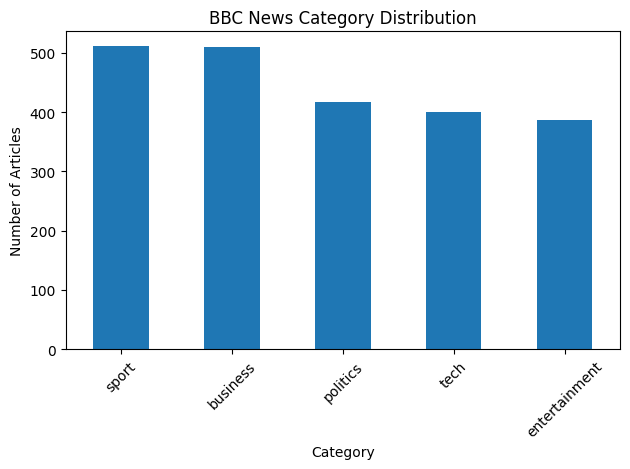

Average text length: 2232.793258426966
Min text length: 471
Max text length: 25454


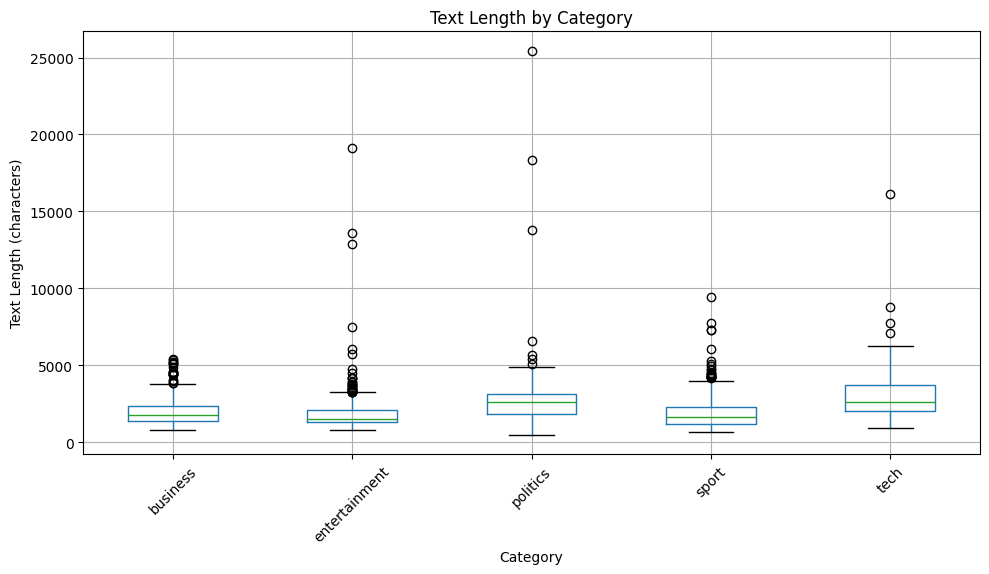

Training set size: 1334
Validation set size: 334
Test set size: 557

Category distribution in training set:
category
business         306
sport            306
politics         250
tech             241
entertainment    231
Name: count, dtype: int64

Category distribution in validation set:
category
sport            77
business         76
politics         63
tech             60
entertainment    58
Name: count, dtype: int64

Category distribution in test set:
category
business         128
sport            128
politics         104
tech             100
entertainment     97
Name: count, dtype: int64


In [3]:
# Explore the first 10 rows
df.head(10) # None

# Basic info and describe
df.describe() # None 
df.info() # None

# Category distribution
category_counts = df['category'].value_counts() # None
category_counts

# Visualize category distribution
category_counts.plot(kind='bar')
plt.xlabel('Category')
plt.ylabel('Number of Articles')
plt.title('BBC News Category Distribution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# None

# Text length analysis
df['text_length'] = df['content'].str.len()
print(f"Average text length: {df['text_length'].mean()}")
print(f"Min text length: {df['text_length'].min()}")
print(f"Max text length: {df['text_length'].max()}")

# Visualize text length by category
df.boxplot(column='text_length', by='category', figsize=(10, 6))
plt.title('Text Length by Category')
plt.suptitle('')  # removes the automatic extra title
plt.xlabel('Category')
plt.ylabel('Text Length (characters)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Check for missing values
df.isna().sum() #None

# Map category labels to integers for classification
categories = list(df['category'].unique())
category_mapping = {category: i for i, category in enumerate(categories)}
df['label'] = df['category'].map(category_mapping)

# Rename content column to text
df.rename(columns={'content': 'text'}, inplace=True)

# Split into train, validation, and test sets, make sure to stratify based on category, keep features and target together for now
# First, create train+validation and test sets
train_val_df, test_df = train_test_split(
    df, 
    test_size=0.25,          # 25 % for the final test set  
    stratify=df['category'], # keep category proportions
    random_state=42
)

#None
# Then split train+validation into separate train and validation sets
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.2,                    # 20 % of the train_val data becomes validation
    stratify= train_val_df['category'], # still keep category balance
    random_state=42
)

# None

print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

# Ensure categories are distributed properly across splits
print("\nCategory distribution in training set:")
print(train_df['category'].value_counts())
print("\nCategory distribution in validation set:")
print(val_df['category'].value_counts())
print("\nCategory distribution in test set:")
print(test_df['category'].value_counts())

## Part 3: Hugging Face Approach
Implement BERT with Hugging Face Transformers
- Import required libraries
- Select and load a BERT model
- Tokenize data
- Create datasets
- Fine-tune the model
- Evaluate performance


In [4]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

In [5]:
# Import Hugging Face libraries
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback
from datasets import Dataset
import torch

# Select and load tokenizer
model_name = 'bert-base-uncased'
tokenizer = BertTokenizer.from_pretrained(model_name) #None

# Convert pandas DataFrames to Hugging Face datasets
train_dataset_hf = Dataset.from_pandas(train_df)
val_dataset_hf = Dataset.from_pandas(val_df)
test_dataset_hf = Dataset.from_pandas(test_df)

# Tokenize function (use 128 for max length)
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

# Tokenize datasets
tokenized_train = train_dataset_hf.map( tokenize_function, batched=True ) # None
tokenized_val = val_dataset_hf.map(tokenize_function, batched=True ) # None
tokenized_test = test_dataset_hf.map(tokenize_function, batched=True ) # None

# Load pre-trained model with classification head
model_hf = BertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=5
) # None
# Set BERT encoder layers to not train
for param in model_hf.bert.parameters():
    param.requires_grad = False
#None

# Define metrics computation function the returns a dictionary of scores - include at least accuracy
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='weighted')
    acc = accuracy_score(labels, preds)
    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision, 
        'recall': recall
    }

# Set up training arguments (train for 5 epochs - not enough to fully train but for sake of time. Set learning rate of 0.0005)
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    warmup_steps=500,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    use_cpu=True, # important for Mac users with M1+ chips
    learning_rate=0.0005
)

# Initialize Trainer - include an early stopping callback with patience of 3
trainer = Trainer(
    model=model_hf,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
    callbacks = [EarlyStoppingCallback(early_stopping_patience=3)])

# Train the model
print('Fine-tuning BERT model with Hugging Face...')
trainer.train()

/usr/local/Caskroom/miniconda/base/envs/learn-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-19 09:39:34.412914: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Map: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 557/557 [00:03<00:00, 159.45 examples/s]
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']


Fine-tuning BERT model with Hugging Face...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,1.596000,1.569382,0.329341,0.270348,0.376854,0.329341
2,1.502100,1.502529,0.413174,0.336888,0.561627,0.413174
3,1.430800,1.417728,0.520958,0.521079,0.589727,0.520958
4,1.339300,1.313232,0.565868,0.547861,0.670434,0.565868
5,1.270600,1.222792,0.601796,0.598193,0.680263,0.601796


TrainOutput(global_step=420, training_loss=1.4521787938617525, metrics={'train_runtime': 729.6012, 'train_samples_per_second': 9.142, 'train_steps_per_second': 0.576, 'total_flos': 438749502558720.0, 'train_loss': 1.4521787938617525, 'epoch': 5.0})

In [6]:
# Evaluate the model
results = trainer.evaluate(tokenized_test) #None
print(f"Hugging Face Model Results: {results}")

Hugging Face Model Results: {'eval_loss': 1.2255088090896606, 'eval_accuracy': 0.6211849192100538, 'eval_f1': 0.6109247859644951, 'eval_precision': 0.7026326024667995, 'eval_recall': 0.6211849192100538, 'eval_runtime': 37.0198, 'eval_samples_per_second': 15.046, 'eval_steps_per_second': 0.243, 'epoch': 5.0}


## Part 4: Model Analysis and Inference
Analyze model performance on testing data
- Create confusion matrix visualization
- Analyze misclassifications
- Identify strengths and weaknesses

### Hugging Face Model


<Figure size 1000x800 with 0 Axes>

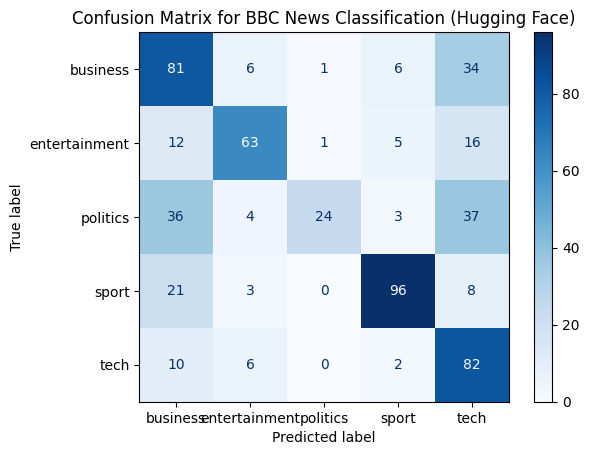


Classification Report:
               precision    recall  f1-score   support

     business       0.51      0.63      0.56       128
entertainment       0.77      0.65      0.70        97
     politics       0.92      0.23      0.37       104
        sport       0.86      0.75      0.80       128
         tech       0.46      0.82      0.59       100

     accuracy                           0.62       557
    macro avg       0.70      0.62      0.61       557
 weighted avg       0.70      0.62      0.61       557


Model Strengths and Weaknesses:

Strengths:
- Overall accuracy: 0.6212
- Best performing category: sport

Weaknesses:
- Worst performing category: politics


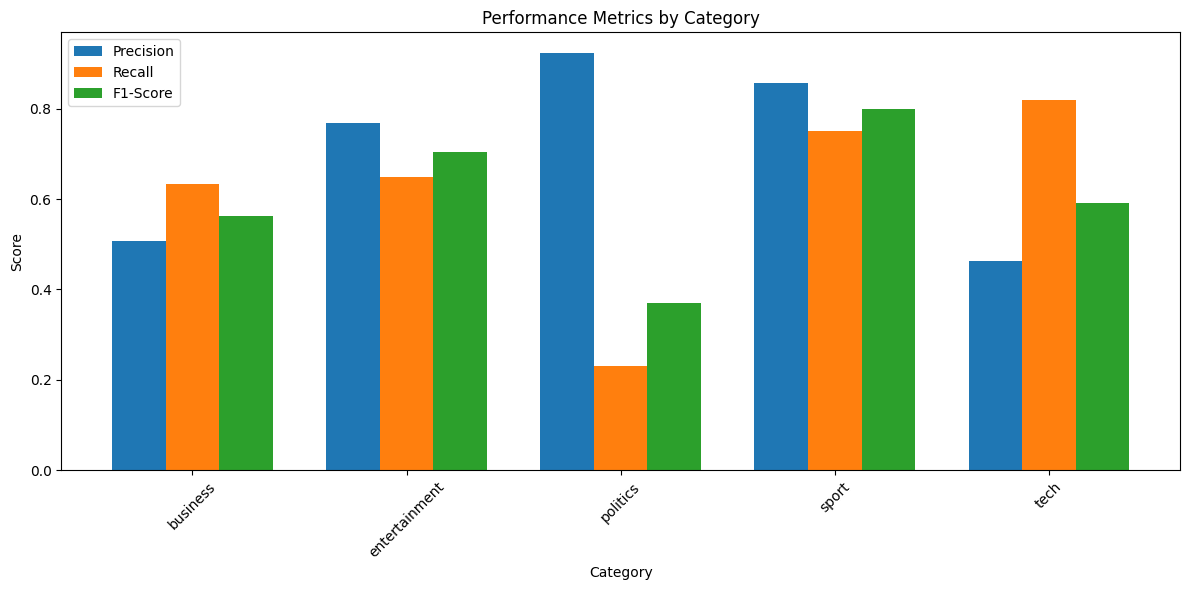

In [7]:
# Generate predictions for the test set
def get_predictions(trainer, dataset):
    # Run predictions with Hugging Face Trainer
    raw_predictions = trainer.predict(dataset)

    # Extract predictions and labels
    predictions = np.argmax(raw_predictions.predictions, axis=1) # None
    labels = raw_predictions.label_ids # None

    return predictions, labels

y_pred, y_true = get_predictions(trainer, tokenized_test)

# Create and visualize the confusion matrix
cm = confusion_matrix( y_true, y_pred ) # None
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories) # None
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix for BBC News Classification (Hugging Face)')
plt.grid(False)
plt.show()

# Create classification report
report = classification_report(y_true,y_pred,target_names=categories, output_dict=True ) # None
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=categories))


# Identify strengths and weaknesses
print("\nModel Strengths and Weaknesses:")

# Calculate per-class metrics (use classification report)
per_class_metrics = {
    cat: report[cat] for cat in categories
}

# Find best and worst performing categories
best_category = max(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])
worst_category = min(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])

print(f"\nStrengths:")
print(f"- Overall accuracy: {report['accuracy']:.4f}")
print(f"- Best performing category: {best_category[0]}")
print(f"\nWeaknesses:")
print(f"- Worst performing category: {worst_category[0]}")

# Visualize per-class performance
plt.figure(figsize=(12, 6))
categories_indices = range(len(categories))
width = 0.25

plt.bar([i - width for i in categories_indices],
        [per_class_metrics[cat]['precision'] for cat in categories],
        width=width, label='Precision')
plt.bar(categories_indices,
        [per_class_metrics[cat]['recall'] for cat in categories],
        width=width, label='Recall')
plt.bar([i + width for i in categories_indices],
        [per_class_metrics[cat]['f1-score'] for cat in categories],
        width=width, label='F1-Score')

plt.xlabel('Category')
plt.ylabel('Score')
plt.title('Performance Metrics by Category')
plt.xticks(categories_indices, categories, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Create a function for model inference on new articles
def predict_article_category(text, model=model_hf, tokenizer=tokenizer):
    """
    Predict the category of a news article using the fine-tuned model.

    Args:
        text (str): The text of the news article
        model: The fine-tuned Hugging Face model
        tokenizer: The tokenizer for the model

    Returns:
        dict: Prediction results including category and confidence scores
    """
    # Tokenize inputs
    inputs = tokenizer(
        text, 
        padding=True, 
        truncation= True, 
        max_length=128, 
        return_tensors = "pt"
    )


    # Get predictions
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        predictions = torch.softmax(logits, dim=1)

    # Convert to numpy for easier handling
    probs = predictions[0].numpy() #None

    # Get the predicted category and confidence
    predicted_class_id = np.argmax( probs ) #None
    predicted_category = categories[predicted_class_id]
    confidence = float(probs[predicted_class_id])

    # Get confidence for all categories
    category_confidences = {categories[i]: float(probs[i]) for i in range(len(categories))}

    # Sort categories by confidence (descending)
    sorted_categories = sorted(category_confidences.items(), key=lambda x: x[1], reverse=True)

    return {
        'text': text[:100] + '...' if len(text) > 100 else text,
        'predicted_category': predicted_category,
        'confidence': confidence,
        'all_confidences': sorted_categories
    }

# Test the inference function with example articles
sample_articles = [
    "The tech giant announced the release of their new smartphone that features advanced AI capabilities and improved battery life. The product will be available in stores next month.",
    "The football team secured their victory in the final minutes with a spectacular goal. The win puts them at the top of the league table.",
    "Stock markets plummeted following the central bank's announcement of interest rate increases. Investors are concerned about the impact on economic growth.",
    "The new film starring the award-winning actress has received critical acclaim at the international film festival. Critics praised the innovative cinematography.",
    "The government announced new policies regarding digital privacy and data protection. Opposition parties have criticized the measures as inadequate."
]

print("\nTesting inference on sample articles:")
for i, article in enumerate(sample_articles):
    result = predict_article_category(article)
    print(f"\nSample {i+1}:")
    print(f"Text: {result['text']}")
    print(f"Predicted category: {result['predicted_category']} (confidence: {result['confidence']:.4f})")
    print("All category confidences:")
    for category, conf in result['all_confidences']:
        print(f"  - {category}: {conf:.4f}")


Testing inference on sample articles:

Sample 1:
Text: The tech giant announced the release of their new smartphone that features advanced AI capabilities ...
Predicted category: business (confidence: 0.3693)
All category confidences:
  - business: 0.3693
  - tech: 0.2103
  - entertainment: 0.1959
  - sport: 0.1307
  - politics: 0.0939

Sample 2:
Text: The football team secured their victory in the final minutes with a spectacular goal. The win puts t...
Predicted category: sport (confidence: 0.3672)
All category confidences:
  - sport: 0.3672
  - entertainment: 0.2694
  - business: 0.1723
  - politics: 0.1042
  - tech: 0.0869

Sample 3:
Text: Stock markets plummeted following the central bank's announcement of interest rate increases. Invest...
Predicted category: business (confidence: 0.4991)
All category confidences:
  - business: 0.4991
  - tech: 0.2005
  - politics: 0.1264
  - entertainment: 0.1118
  - sport: 0.0622

Sample 4:
Text: The new film starring the award-winning actress

# Part 5: Conclusion and Discussion
Summarize your findings
- What was the final accuracy and other metrics?
```
On the held-out test set the model reached an accuracy of 0.6212. The weighted-average F1-score was 0.6109, with weighted precision 0.7026 and weighted recall 0.6212. These figures come from trainer.evaluate(tokenized_test) and the classification report. The relatively modest scores reflect the fact that the BERT encoder was completely frozen and only the classification head was trained for five epochs.

```
  
- What categories were easiest/hardest to classify
```

Sport was the easiest category to classify (F1 = 0.80), followed by entertainment (F1 = 0.70). Politics was the hardest (F1 = 0.37), driven largely by very low recall (0.23). Business and tech fell in the middle (F1 ≈ 0.56–0.59). Sport articles tend to contain highly distinctive vocabulary, while politics overlaps more with business and current-affairs language, making it harder for a frozen encoder to separate cleanly.
```


- What challenges did you encounter?
```
Freezing the entire BERT encoder limited adaptation; only the final classification layer could learn.
Training for only five epochs with a learning rate of 0.0005 was insufficient for the head to fully converge.
Truncation at 128 tokens discarded substantial context from longer articles.
Topical overlap (especially politics ↔ business) produced systematic confusions visible in the confusion matrix.
Running on CPU made iteration slower.
```


- How might you improve the model further?

```
Unfreeze the last 2–4 transformer layers (or the whole model) and fine-tune with a lower learning rate (e.g., 2e-5).
Train for more epochs while retaining early stopping.
Increase max_length to 256 so less text is truncated.
Try a larger checkpoint or a news-domain model.
Add class weights or focal loss to help the low-recall politics class.
Experiment with a slightly deeper classification head.
```
